<a href="https://colab.research.google.com/github/fboldt/aulasml/blob/master/aula10b_knn_predict_proba.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Accuracy of KNN classifier: 0.9298245614035088
              precision    recall  f1-score   support

           0       0.93      0.88      0.90        43
           1       0.93      0.96      0.94        71

    accuracy                           0.93       114
   macro avg       0.93      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



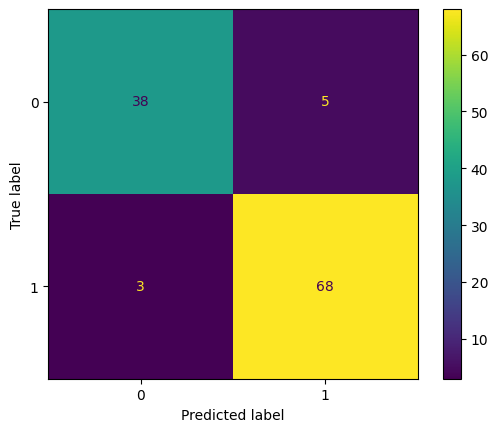

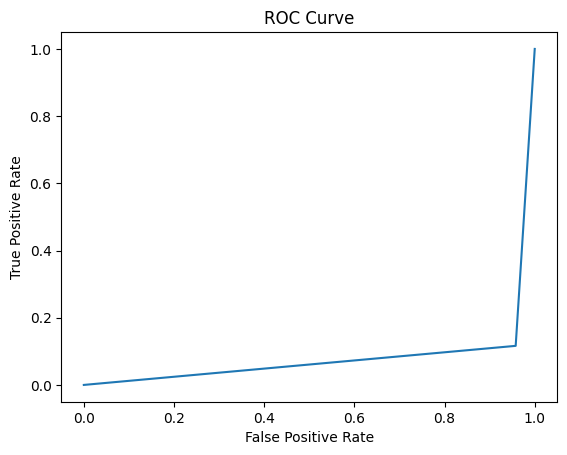

In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=3)
knn_clf.fit(X_train, y_train)
knn_pred = knn_clf.predict(X_test)
print(f"Accuracy of KNN classifier: {knn_clf.score(X_test, y_test)}")

print(classification_report(y_test, knn_pred))

cm = confusion_matrix(y_test, knn_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_clf.classes_)
disp.plot()
plt.show()

tpr, fpr, thresholds = roc_curve(y_test, knn_pred)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

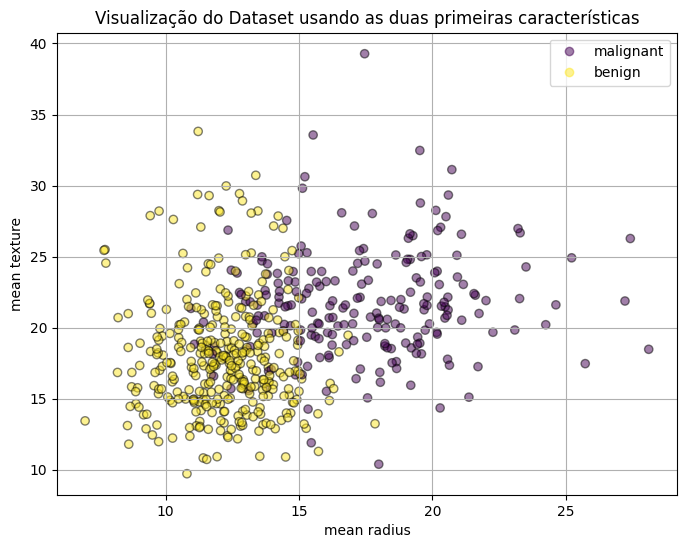

In [12]:
import matplotlib.pyplot as plt

# Selecionando as duas primeiras características (colunas 0 e 1)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.5)

plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])
plt.title('Visualização do Dataset usando as duas primeiras características')
plt.legend(handles=scatter.legend_elements()[0], labels=list(data.target_names))
plt.grid(True)
plt.show()